# De-convolutional Autoencoder
###### MNIST reconstruction

Import dependencies

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
%matplotlib inline

#### Util functions

function to plot the images after during testing phase

In [2]:
def plot_images(images, title, no_i_x, no_i_y=2):
    fig = plt.figure(figsize=(5, 15))
    fig.canvas.manager.set_window_title(title)
    images = np.array(images).reshape(-1, 28, 28)
    for i in range(no_i_x):
        for j in range(no_i_y):
            ax = fig.add_subplot(no_i_x, no_i_y, no_i_x * j + (i + 1))
            ax.matshow(images[no_i_x * j + i], cmap="gray")
            plt.xticks([])
            plt.yticks([])

            if j == 0 and i == 0:
                ax.set_title("Real")
            elif j == 0 and i == 1:
                ax.set_title("Reconstructed")

load the mnist dataset

In [3]:
(x_train_raw, _), (x_test_raw, _) = tf.keras.datasets.mnist.load_data()
x_train = (x_train_raw.reshape(-1, 28 * 28).astype(np.float32)) / 255.0
x_test = (x_test_raw.reshape(-1, 28 * 28).astype(np.float32)) / 255.0
x_val = x_train[55000:]
x_train = x_train[:55000]

### Neural Network Model
Encoder = 2 convolutional layers + 1 fully connected layer<br>
Decoder = 2 de-convolutional layers + 1 fully connected layer<br>

<br>Hyper-parameters

In [4]:
n_image_width = 28
n_image_height = 28
n_input_pixels = n_image_height * n_image_width
filter_width = 5
filter_height = 5
n_channels = 1  # black

conv_1_features = 16
conv_2_features = 32

final_hid_lay = 196

learning_rate = 0.001
batch_size = 20

images_to_plot = 10

Layer Weights and biases

In [5]:
conv_lay_1 = {
    'weight': tf.Variable(
        tf.random.normal([filter_height, filter_width, n_channels, conv_1_features], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([conv_1_features], stddev=0.1))
}
conv_lay_2 = {
    'weight': tf.Variable(
        tf.random.normal([filter_height, filter_width, conv_1_features, conv_2_features], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([conv_2_features], stddev=0.1))
}
fc_enc_lay_1 = {
    'weight': tf.Variable(
        tf.random.normal([7 * 7 * conv_2_features, final_hid_lay], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([final_hid_lay], stddev=0.1))
}

deconv_lay_1 = {
    'weight': tf.Variable(
        tf.random.normal([filter_height, filter_width, conv_1_features, conv_2_features], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([conv_1_features], stddev=0.1))
}
deconv_lay_2 = {
    'weight': tf.Variable(
        tf.random.normal([filter_height, filter_width, n_channels, conv_1_features], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([n_channels], stddev=0.1))
}
fc_dec_lay_2 = {
    'weight': tf.Variable(
        tf.random.normal([final_hid_lay, 7 * 7 * conv_2_features], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([7 * 7 * conv_2_features], stddev=0.1))
}

trainable_variables = [
    conv_lay_1['weight'], conv_lay_1['bias'],
    conv_lay_2['weight'], conv_lay_2['bias'],
    fc_enc_lay_1['weight'], fc_enc_lay_1['bias'],
    fc_dec_lay_2['weight'], fc_dec_lay_2['bias'],
    deconv_lay_1['weight'], deconv_lay_1['bias'],
    deconv_lay_2['weight'], deconv_lay_2['bias']
]

#### Model

In [6]:
def model(X):
    # Encoder -> 2 convoltional layers (without max-pooling)
    # Resize image to proper shape
    x_img = tf.reshape(X, [-1, n_image_width, n_image_height,
                           n_channels])  # [batch, height, width, channels]

    conv_1 = tf.nn.conv2d(x_img, conv_lay_1['weight'], strides=[1, 2, 2, 1], padding='SAME')
    conv_1_op = tf.nn.relu(conv_1 + conv_lay_1['bias'])

    conv_2 = tf.nn.conv2d(conv_1_op, conv_lay_2['weight'], strides=[1, 2, 2, 1], padding='SAME')
    conv_2_op = tf.nn.relu(conv_2 + conv_lay_2['bias'])

    # Encoder -> 1 fully connected layer
    flat_lay = tf.reshape(conv_2_op, [-1, 7 * 7 * conv_2_features])
    enc_1 = tf.matmul(flat_lay, fc_enc_lay_1['weight']) + fc_enc_lay_1['bias']
    enc_op = tf.nn.relu(enc_1)

    # Decoder -> 1 fully connected layer
    dec_1 = tf.matmul(enc_op, fc_dec_lay_2['weight']) + fc_dec_lay_2['bias']
    dec_flat = tf.nn.relu(dec_1)
    dec_op = tf.reshape(dec_flat, [-1, 7, 7, conv_2_features])

    # Decoder -> 2 de-convoltional layers
    b = tf.shape(X)[0]
    dconv_1 = tf.nn.conv2d_transpose(
        dec_op,
        deconv_lay_1['weight'],
        strides=[1, 2, 2, 1],
        output_shape=[
            b, n_image_width // 2, n_image_height // 2, conv_1_features
        ],
        padding='SAME')
    dconv_1_op = tf.nn.relu(dconv_1 + deconv_lay_1['bias'])

    dconv_2 = tf.nn.conv2d_transpose(
        dconv_1_op,
        deconv_lay_2['weight'],
        strides=[1, 2, 2, 1],
        output_shape=[b, n_image_width, n_image_height, n_channels],
        padding='SAME')
    dconv_2_op = tf.nn.relu(dconv_2 + deconv_lay_2['bias'])
    return dconv_2_op

#### Error and Optimizer

In [7]:
# mean-squared error
def compute_error(reconstructed, x_orig):
    x_img = tf.reshape(x_orig, [-1, n_image_width, n_image_height, n_channels])
    return tf.reduce_mean(0.5 * tf.square(reconstructed - x_img))


# adam-optimizer
optimizer = tf.optimizers.Adam(learning_rate)


@tf.function
def train_step(x_batch):
    with tf.GradientTape() as tape:
        reconstructed = model(x_batch)
        err = compute_error(reconstructed, x_batch)
    grads = tape.gradient(err, trainable_variables)
    optimizer.apply_gradients(zip(grads, trainable_variables))
    return err

#### Start Training

In [8]:
disp_imgs = []

print("*********** Train ***********")

train_examples = len(x_train)

for i in range(train_examples // batch_size):
    x_batch = x_train[i * batch_size:(i + 1) * batch_size]
    err = train_step(x_batch)

    if i % 100 == 0 and i != 0:
        val_batch = x_val[:batch_size]
        val_err = compute_error(model(val_batch), val_batch)
        print("Batch: %d validation-error = %f" % (i, val_err))

print("*********** Test ***********")
test_batch = x_test[:batch_size]
reconstructed_imgs = model(test_batch)
test_err = compute_error(reconstructed_imgs, test_batch)

print("Test Error: %.8f" % test_err)

for i in range(images_to_plot):
    disp_imgs.append(test_batch[i].reshape(-1, 28, 28))
    disp_imgs.append(reconstructed_imgs[i].numpy().reshape(-1, 28, 28))

*********** Train ***********
Batch: 100 validation-error = 0.018253
Batch: 200 validation-error = 0.011290
Batch: 300 validation-error = 0.008204
Batch: 400 validation-error = 0.007391
Batch: 500 validation-error = 0.006252
Batch: 600 validation-error = 0.005586
Batch: 700 validation-error = 0.005325
Batch: 800 validation-error = 0.004678
Batch: 900 validation-error = 0.004291
Batch: 1000 validation-error = 0.003982
Batch: 1100 validation-error = 0.003896
Batch: 1200 validation-error = 0.003533
Batch: 1300 validation-error = 0.003424
Batch: 1400 validation-error = 0.003259
Batch: 1500 validation-error = 0.003103
Batch: 1600 validation-error = 0.002972
Batch: 1700 validation-error = 0.002844
Batch: 1800 validation-error = 0.002930
Batch: 1900 validation-error = 0.002770
Batch: 2000 validation-error = 0.002639
Batch: 2100 validation-error = 0.002543
Batch: 2200 validation-error = 0.002417
Batch: 2300 validation-error = 0.002486
Batch: 2400 validation-error = 0.002353
Batch: 2500 validat

#### plot output

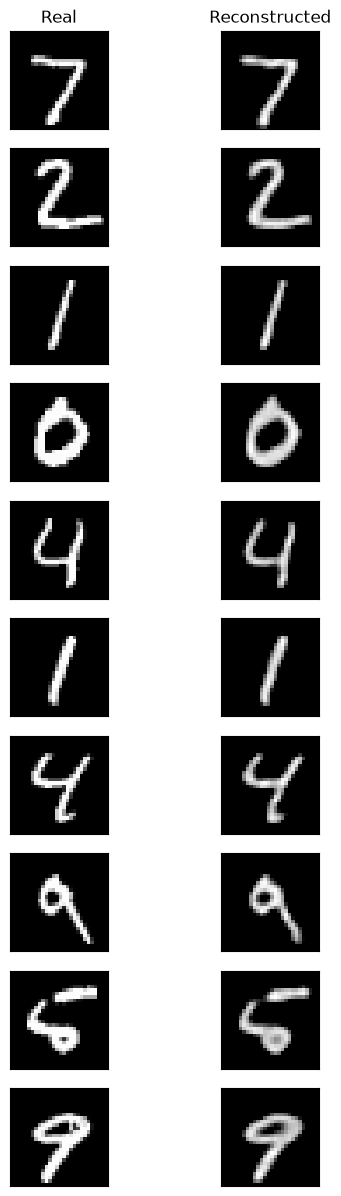

In [9]:
plot_images(disp_imgs, "Auto-encoder", images_to_plot)
plt.show()